Taking the feasible options visualizations from parallel_trend_visualisations and now visualizing the parallel-trends to present:

feasible for the parallel-trend assupmtion are:

    ("Aargau", "Basel-Stadt"),
    ("Aargau", "Genf"),
    ("Aargau", "Neuenburg"),
    ("Basel-Stadt", "Bern"),
    ("Basel-Stadt", "Solothurn"),
    ("Basel-Stadt", "St. Gallen"),
    ("Basel-Stadt", "Thurgau"),
    ("Genf", "Luzern"), 
    ("Neuenburg", "St. Gallen"),
    ("Genf", "Wallis")


In [1]:
#reading data
%cd "/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/DAwP Project/Python-Project-HS26-Criminality-and-Minimum-Wage/Group_project_part_annette"
%pwd

import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("Crime_Pop_clean.csv")


#keeping the feasible pairs --> modifying code from parallel_trend_visualisations

import itertools

unique_cantons = data['Canton'].unique()

canton_pairs = list(itertools.combinations(unique_cantons, 2)) #itertools.combinations(..., 2) for paring every item with every other item in the list in groups of 2, ensuring that no canton is paired with itself

print(canton_pairs)

#minimum wage introduced in Neuenburg, Jura, Genf, Tessin, Basel-Stadt --> we only have Neuenburg, Genf, Basel-Stadt in our dataset

target_cantons = ["Neuenburg", "Genf", "Basel-Stadt"]

# Filtering canton_pairs list
combinations = [
    pair for pair in canton_pairs
    if any(canton in target_cantons for canton in pair)] #any(...) checks if at least one of the cantons in the current pair is present, only keeps those

print(combinations)


/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/DAwP Project/Python-Project-HS26-Criminality-and-Minimum-Wage/Group_project_part_annette
[('Aargau', 'Basel-Landschaft'), ('Aargau', 'Basel-Stadt'), ('Aargau', 'Bern'), ('Aargau', 'Freiburg'), ('Aargau', 'Genf'), ('Aargau', 'Luzern'), ('Aargau', 'Neuenburg'), ('Aargau', 'Solothurn'), ('Aargau', 'St. Gallen'), ('Aargau', 'Thurgau'), ('Aargau', 'Waadt'), ('Aargau', 'Wallis'), ('Aargau', 'Zürich'), ('Basel-Landschaft', 'Basel-Stadt'), ('Basel-Landschaft', 'Bern'), ('Basel-Landschaft', 'Freiburg'), ('Basel-Landschaft', 'Genf'), ('Basel-Landschaft', 'Luzern'), ('Basel-Landschaft', 'Neuenburg'), ('Basel-Landschaft', 'Solothurn'), ('Basel-Landschaft', 'St. Gallen'), ('Basel-Landschaft', 'Thurgau'), ('Basel-Landschaft', 'Waadt'), ('Basel-Landschaft', 'Wallis'), ('Basel-Landschaft', 'Zürich'), ('Basel-Stadt', 'Bern'), ('Basel-Stadt', 'Freiburg'), ('Basel-Stadt', 'Genf'), ('Basel-Stadt', 'Luzern'), ('Basel-Stadt', 'Neuenburg'), (

In [2]:
feasible = [
    ("Aargau", "Basel-Stadt"),
    ("Aargau", "Genf"),
    ("Aargau", "Neuenburg"),
    ("Basel-Stadt", "Bern"),
    ("Basel-Stadt", "Solothurn"),
    ("Basel-Stadt", "St. Gallen"),
    ("Basel-Stadt", "Thurgau"),
    ("Genf", "Luzern"), 
    ("Neuenburg", "St. Gallen"),
    ("Genf", "Wallis")]

combinations = [pair for pair in canton_pairs if tuple(sorted(pair)) in feasible]

print(combinations)


[('Aargau', 'Basel-Stadt'), ('Aargau', 'Genf'), ('Aargau', 'Neuenburg'), ('Basel-Stadt', 'Bern'), ('Basel-Stadt', 'Solothurn'), ('Basel-Stadt', 'St. Gallen'), ('Basel-Stadt', 'Thurgau'), ('Genf', 'Luzern'), ('Genf', 'Wallis'), ('Neuenburg', 'St. Gallen')]


In [3]:
import numpy as np
data['AccusedLog'] = (np.log(data['AccusedRate']))
print(data.head())

             Canton  Year         Type of Residence  Resident Population  \
0            Aargau  2010  Ständige Wohnbevölkerung                79369   
1  Basel-Landschaft  2010  Ständige Wohnbevölkerung                30893   
2       Basel-Stadt  2010  Ständige Wohnbevölkerung                24488   
3              Bern  2010  Ständige Wohnbevölkerung               120344   
4          Freiburg  2010  Ständige Wohnbevölkerung                36620   

   Total Residential Population  Percentage of Total Resident Population  \
0                       1006333                                 7.886952   
1                       1006333                                 3.069859   
2                       1006333                                 2.433389   
3                       1006333                                11.958666   
4                       1006333                                 3.638955   

  Age group  Number of Accused Persons  AccusedRate  AccusedLog  
0     20-29         

In [4]:
%cd "/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/DAwP Project/Python-Project-HS26-Criminality-and-Minimum-Wage/Group_project_part_annette/Data_cleaning_and_merging"
%pwd
data.to_csv("Crime_Pop_log.csv", index=False)

/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/DAwP Project/Python-Project-HS26-Criminality-and-Minimum-Wage/Group_project_part_annette/Data_cleaning_and_merging


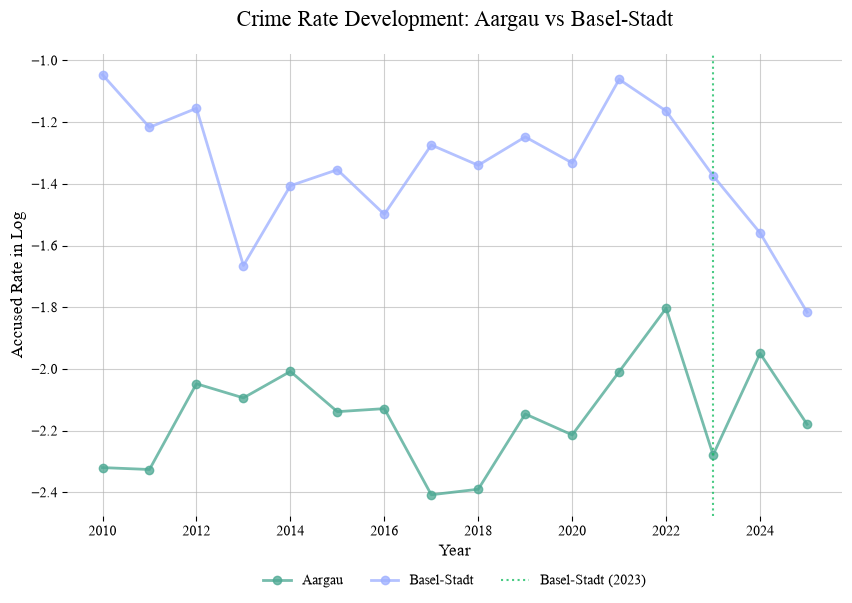

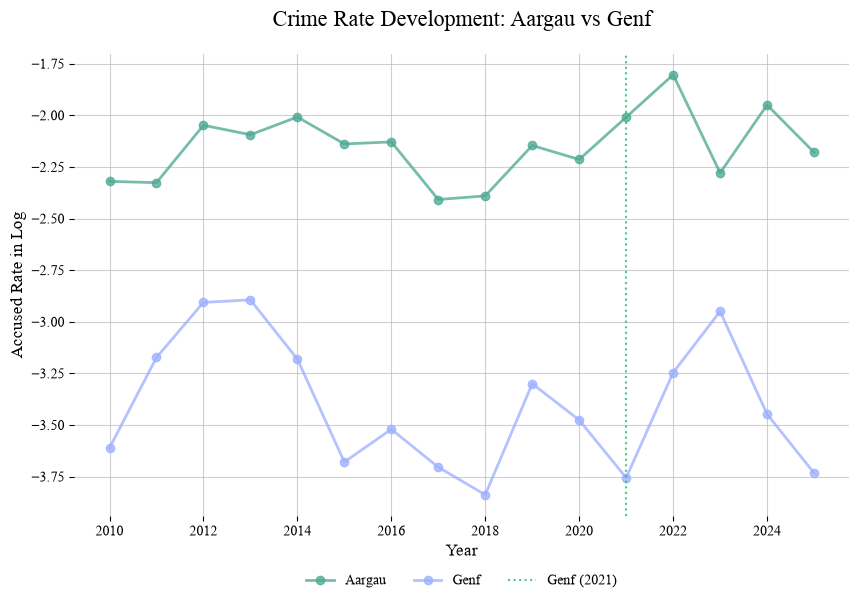

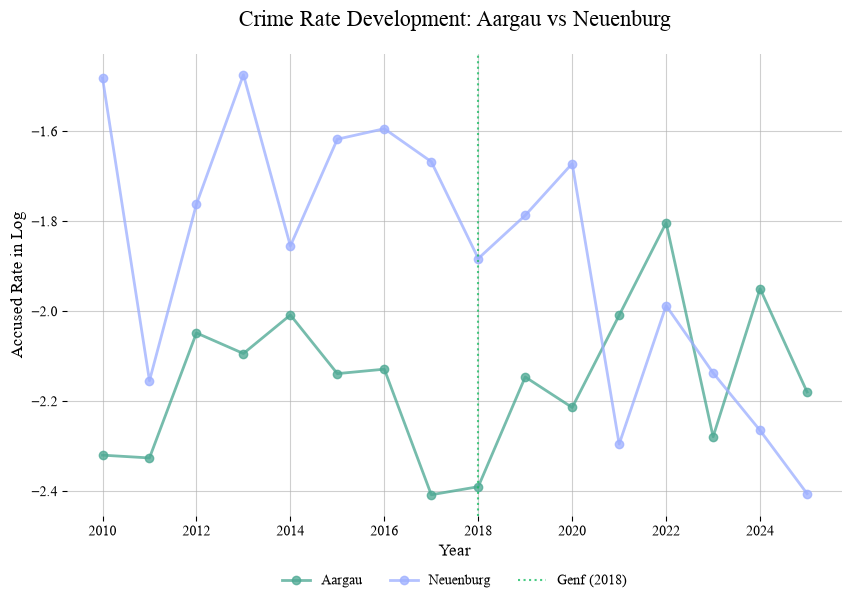

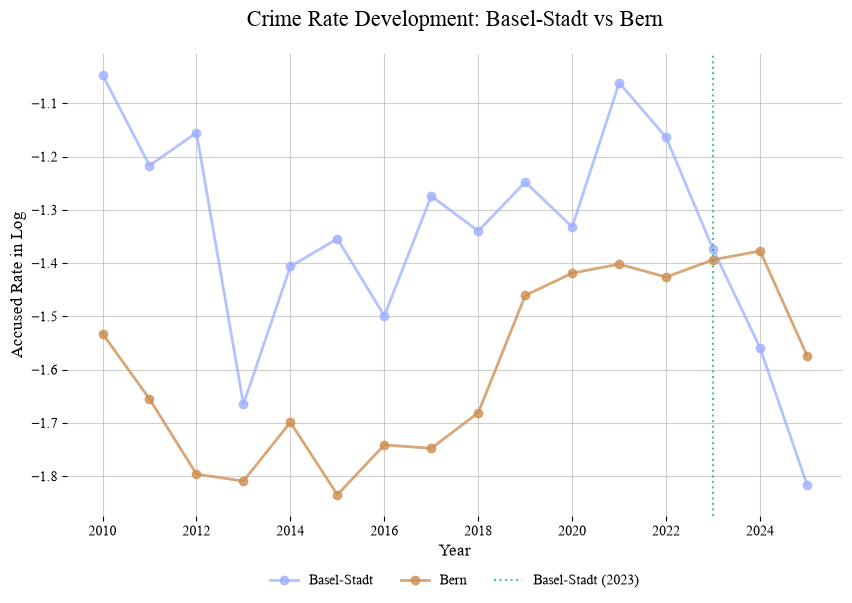

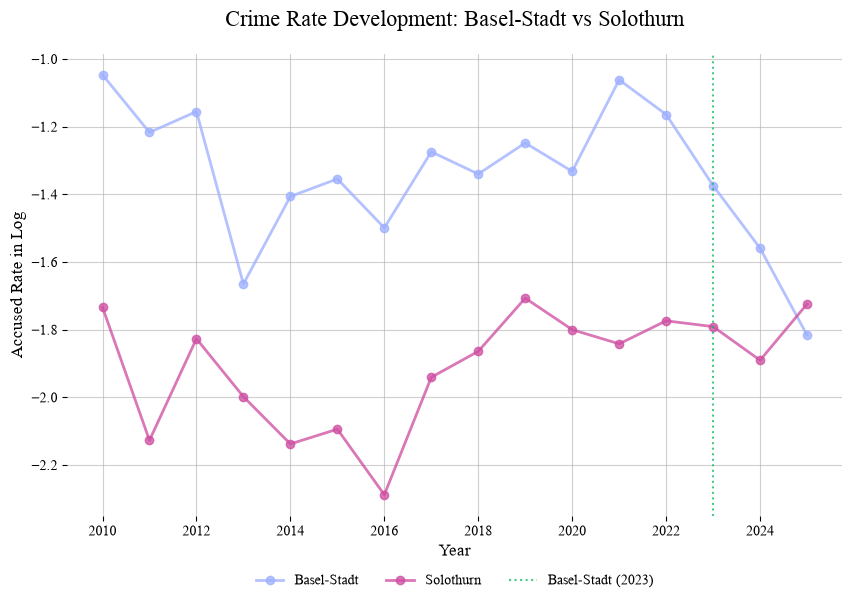

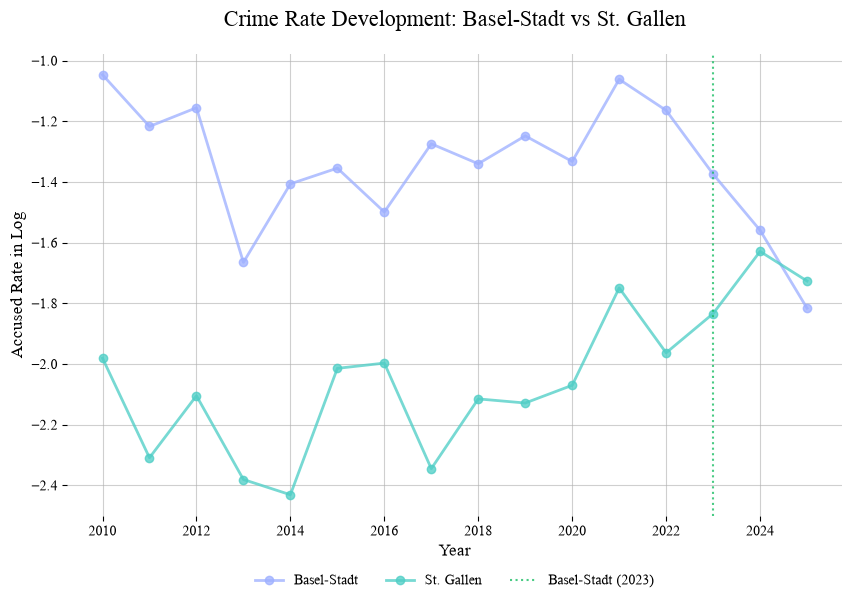

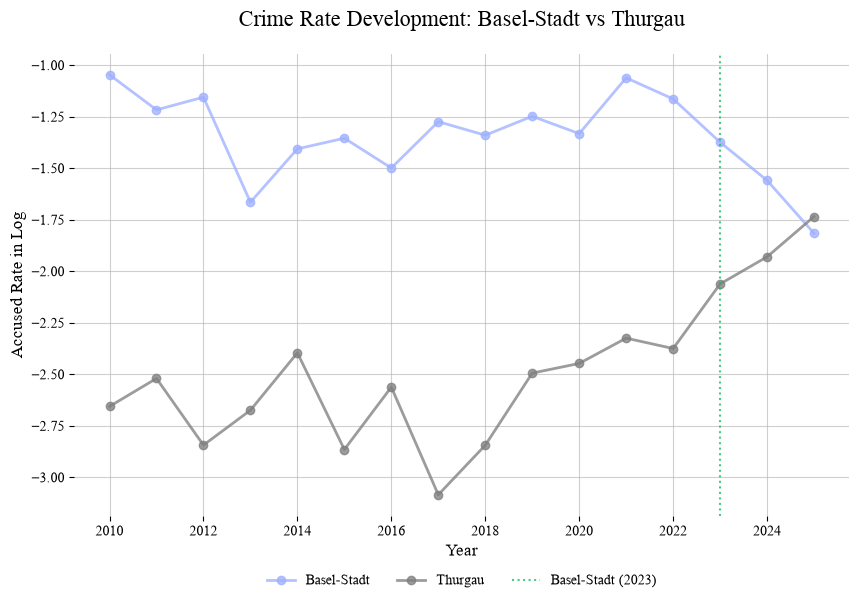

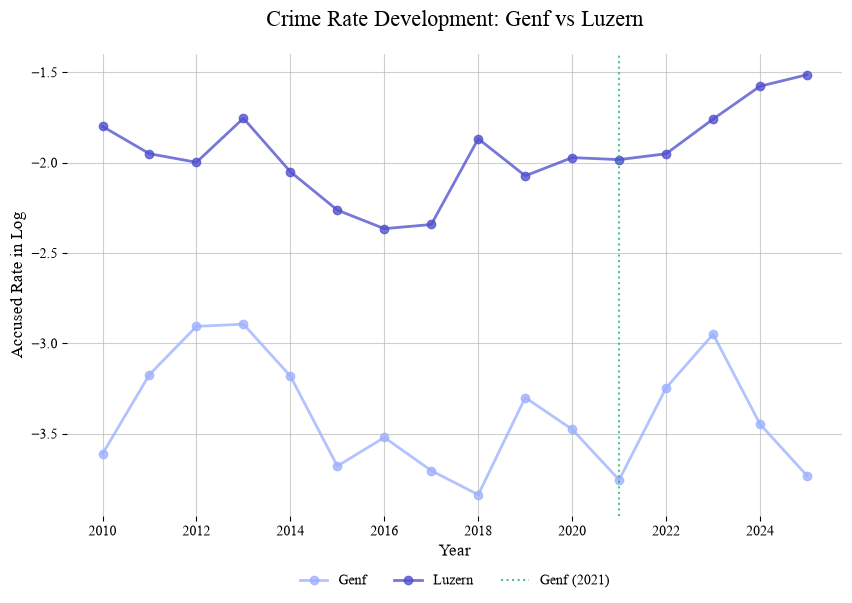

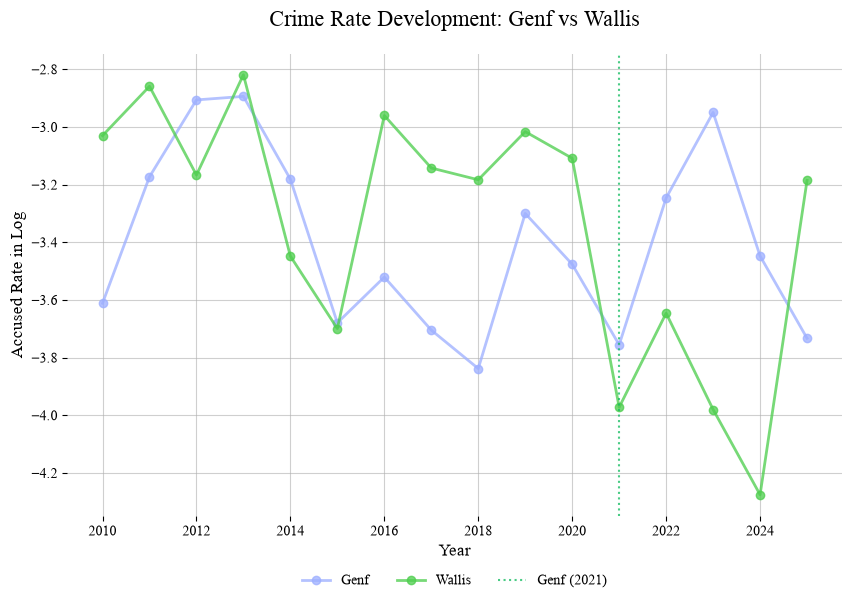

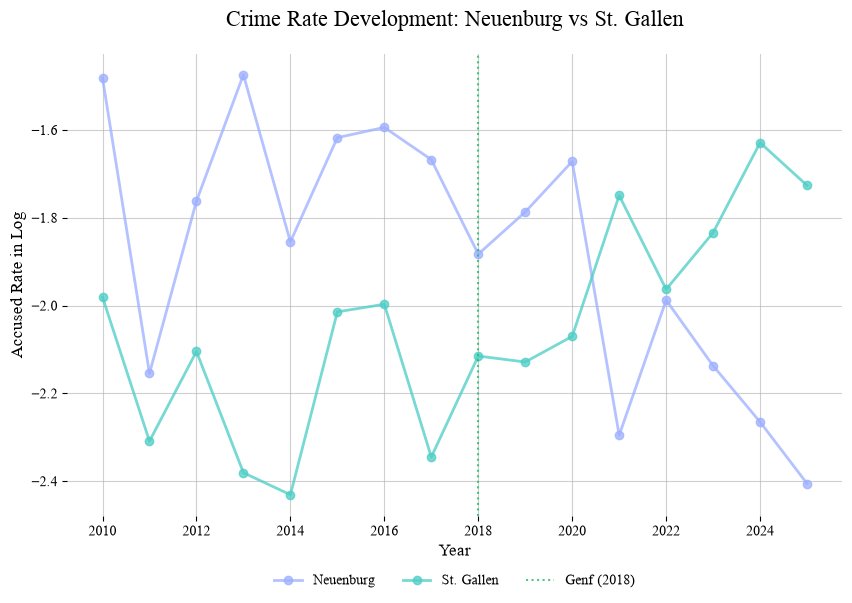

In [ ]:
#WITH LOG ACCUSED RATE

plt.rcParams['font.family'] = 'Times New Roman'
colour1 = "#14BC60C5"
colour_cantons = {
    "Aargau":           "#4EA994C5",  # purple
    "Basel-Stadt":      "#9EB0FFC5",  # yellow-green
    "Bern":             "#CE8E4FC5",  # orange
    "Genf":             "#9EB0FFC5",  # red
    "Luzern":           "#4F4FCEC5",  # indigo
    "Neuenburg":        "#9EB0FFC5",  # light blue
    "Solothurn":        "#CE4FA2C5",  # pink
    "St. Gallen":       "#4FCEC6C5",  # cyan
    "Thurgau":          "#7F7F7FC5",  # gray
    "Wallis":           "#4FCE4FC5",  # green
    }

for canton1, canton2 in combinations:
  
  # 1. Filtering subset for the current pair of cantons
  subset = data[data['Canton'].isin([canton1, canton2])]

  # 2. Creating canvas
  plt.figure(figsize=(10, 6))

  # 3. Ploting both cantons onto same graph
  for canton in [canton1, canton2]:
    canton_data = subset[subset['Canton'] == canton]
    plt.plot(
        canton_data['Year'], 
        canton_data['AccusedLog'],
        marker='o', 
        color=colour_cantons[canton],
        linewidth=2, 
        label=canton)
  if 'Basel-Stadt' in [canton1, canton2]: #adding dotted line for minimum-wage-introduction
    plt.axvline(
      x=2023,
      color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Basel-Stadt (2023)')
  elif 'Genf' in [canton1, canton2]:
    plt.axvline(
      x=2021,
      color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Genf (2021)')
  elif 'Neuenburg' in [canton1, canton2]:
    plt.axvline(
      x=2018,
     color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Genf (2018)')


  

  # 4. Add titles, labels, and show the plot
  plt.title(f'Crime Rate Development: {canton1} vs {canton2}', fontsize=16, pad = 20)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel('Accused Rate in Log', fontsize=12)
  plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=3, frameon=False )
  plt.grid(True, linestyle='-', alpha=0.6)
  for spine in plt.gca().spines.values():
    spine.set_visible(False)
  plt.show()

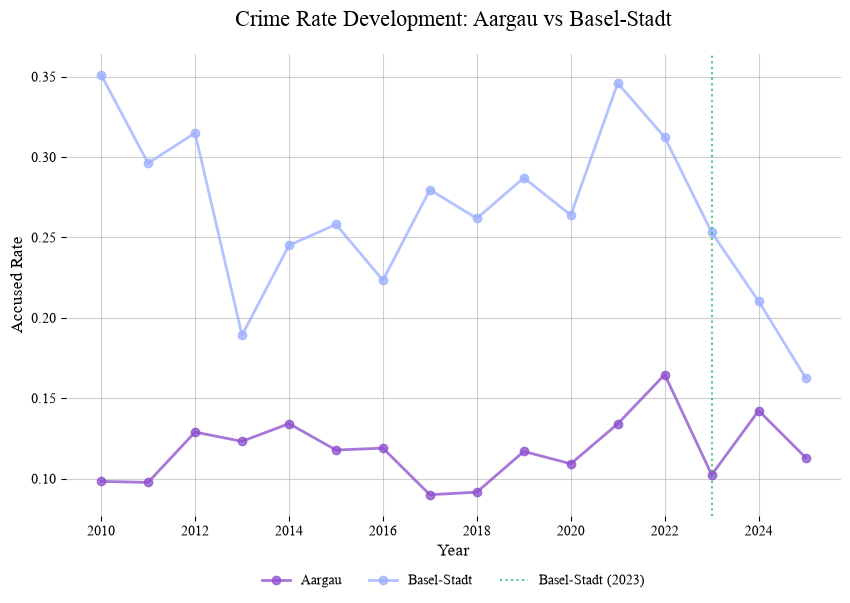

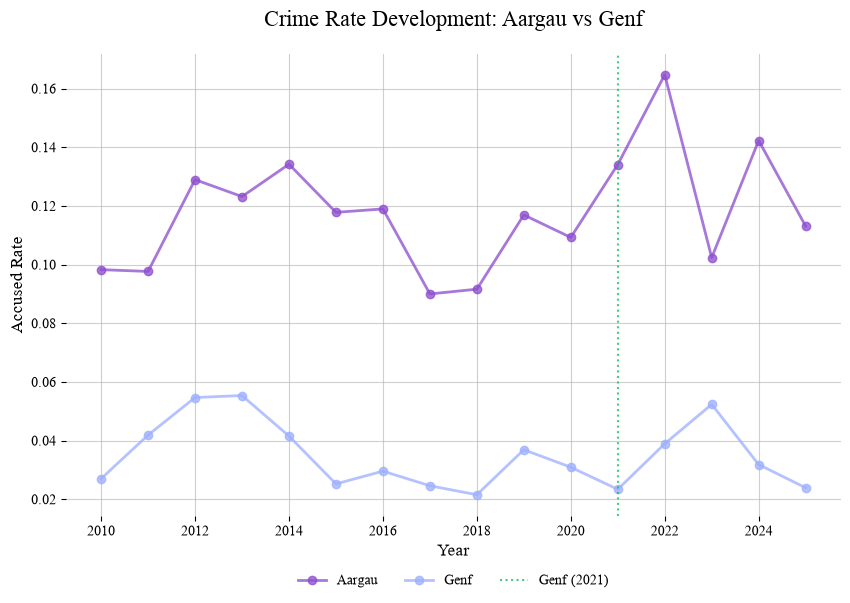

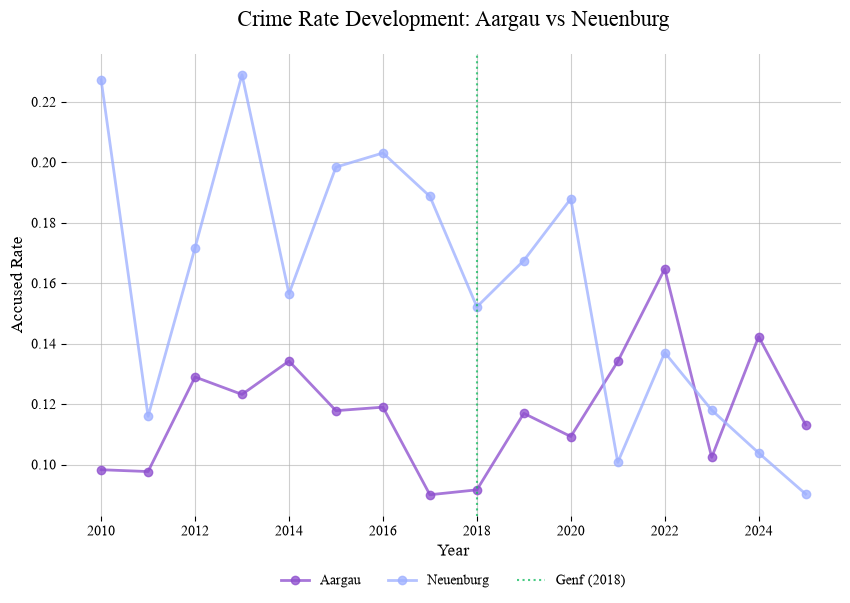

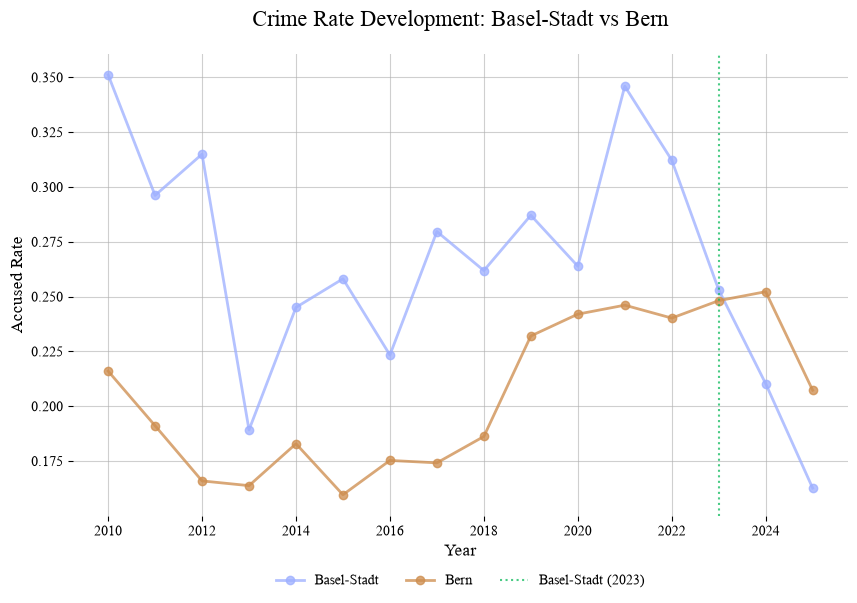

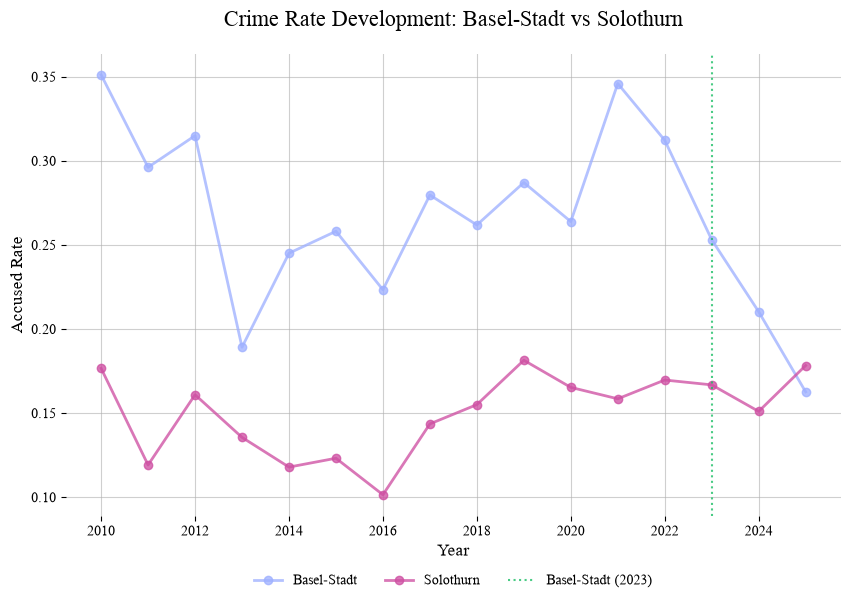

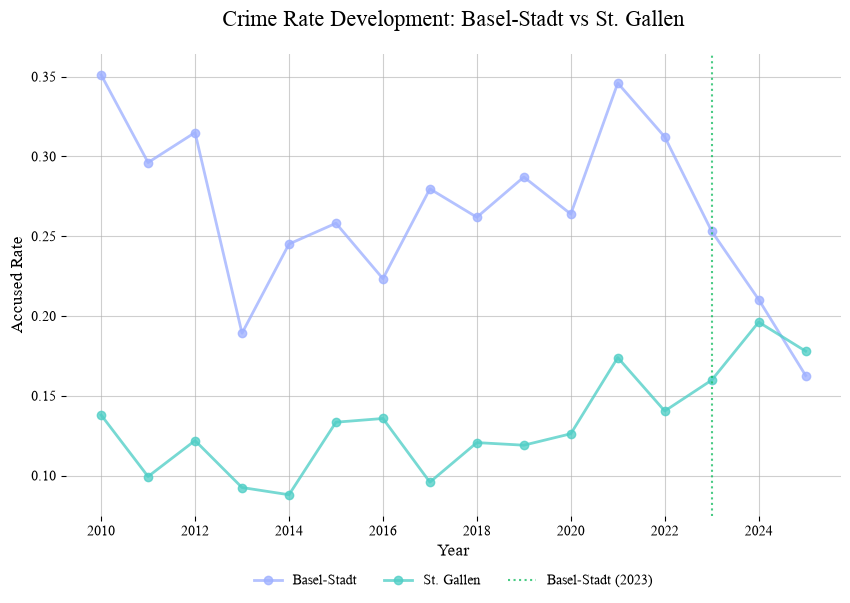

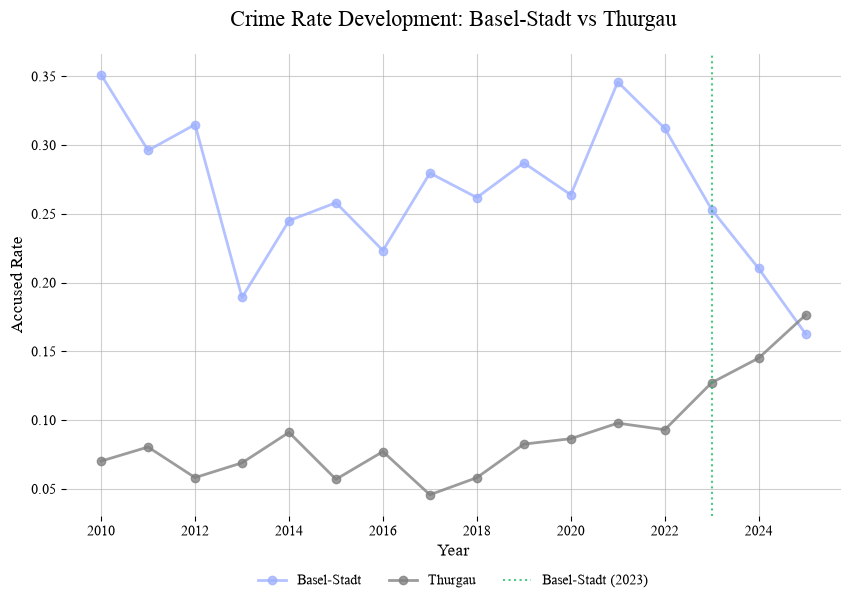

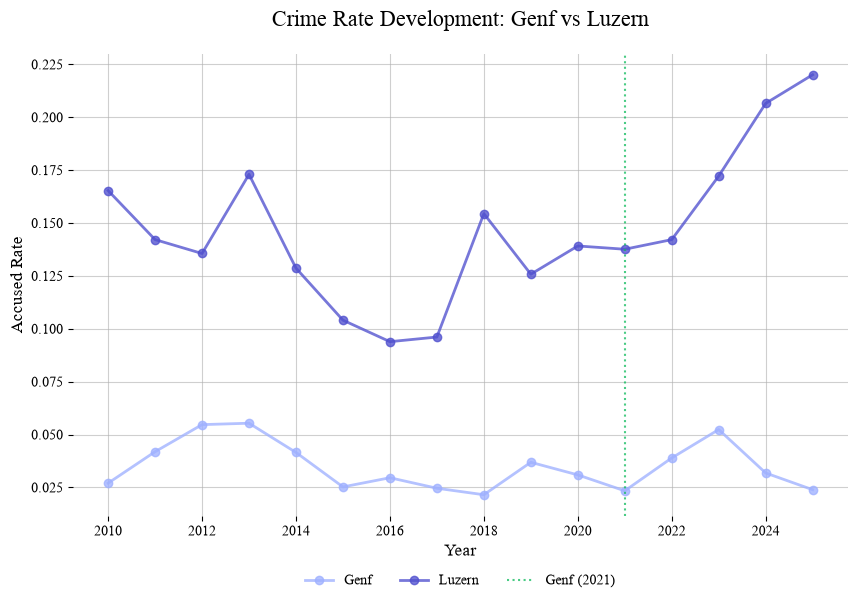

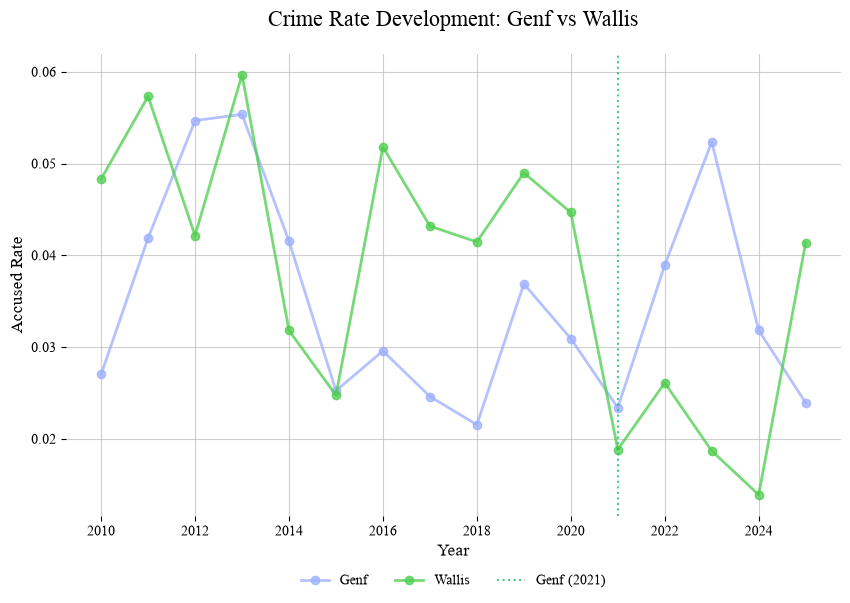

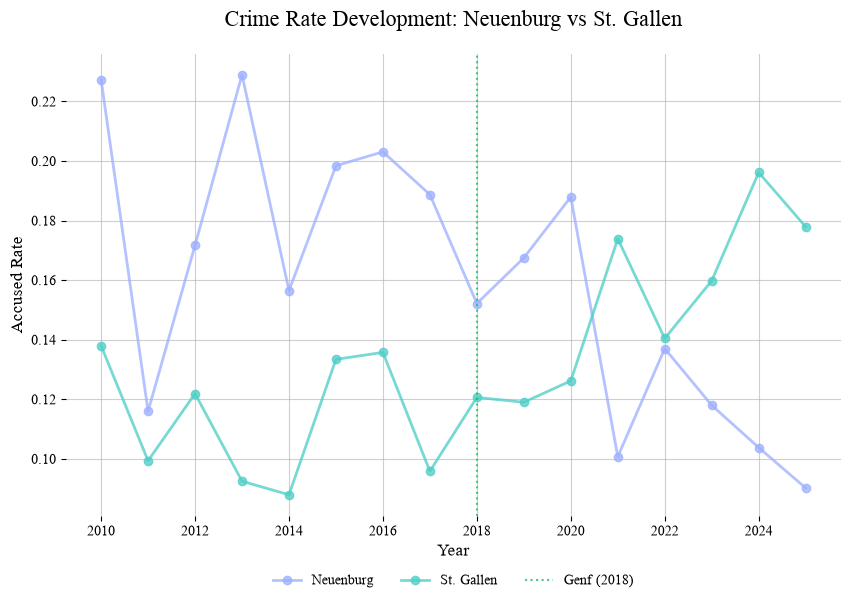

In [ ]:
#WITH ACCUSED RATE (W/O LOG)

plt.rcParams['font.family'] = 'Times New Roman'
colour1 = "#14BC60C5"
colour_cantons = {
    "Aargau":           "#8E4FCEC5",  # purple
    "Basel-Landschaft": "#4FCE8EC5",  # mint
    "Basel-Stadt":      "#9EB0FFC5",  # yellow-green
    "Bern":             "#CE8E4FC5",  # orange
    "Genf":             "#9EB0FFC5",  # red
    "Luzern":           "#4F4FCEC5",  # indigo
    "Neuenburg":        "#9EB0FFC5",  # light blue
    "Solothurn":        "#CE4FA2C5",  # pink
    "St. Gallen":       "#4FCEC6C5",  # cyan
    "Thurgau":          "#7F7F7FC5",  # gray
    "Wallis":           "#4FCE4FC5",  # green
    }

for canton1, canton2 in combinations:
  
  # 1. Filtering subset for the current pair of cantons
  subset = data[data['Canton'].isin([canton1, canton2])]

  # 2. Creating canvas
  plt.figure(figsize=(10, 6))

  # 3. Ploting both cantons onto same graph
  for canton in [canton1, canton2]:
    canton_data = subset[subset['Canton'] == canton]
    plt.plot(
        canton_data['Year'], 
        canton_data['AccusedRate'],
        marker='o', 
        color=colour_cantons[canton],
        linewidth=2, 
        label=canton)
  if 'Basel-Stadt' in [canton1, canton2]: #adding dotted line for minimum-wage-introduction
    plt.axvline(
      x=2023,
      color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Basel-Stadt (2023)')
  elif 'Genf' in [canton1, canton2]:
    plt.axvline(
      x=2021,
      color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Genf (2021)')
  elif 'Neuenburg' in [canton1, canton2]:
    plt.axvline(
      x=2018,
     color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Genf (2018)')


  

  # 4. Add titles, labels, and show the plot
  plt.title(f'Crime Rate Development: {canton1} vs {canton2}', fontsize=16, pad = 20)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel('Accused Rate', fontsize=12)
  plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=3, frameon=False )
  plt.grid(True, linestyle='-', alpha=0.6)
  for spine in plt.gca().spines.values():
    spine.set_visible(False)
  plt.show()

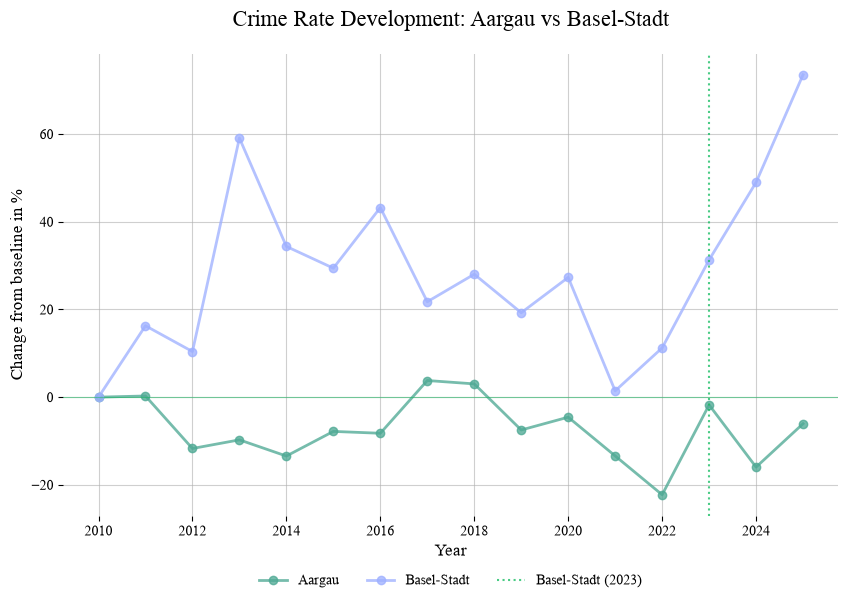

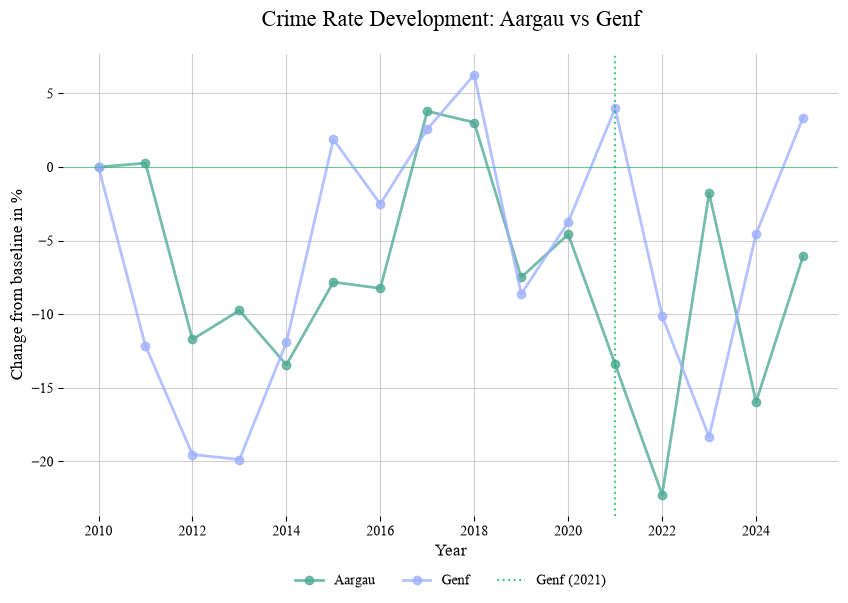

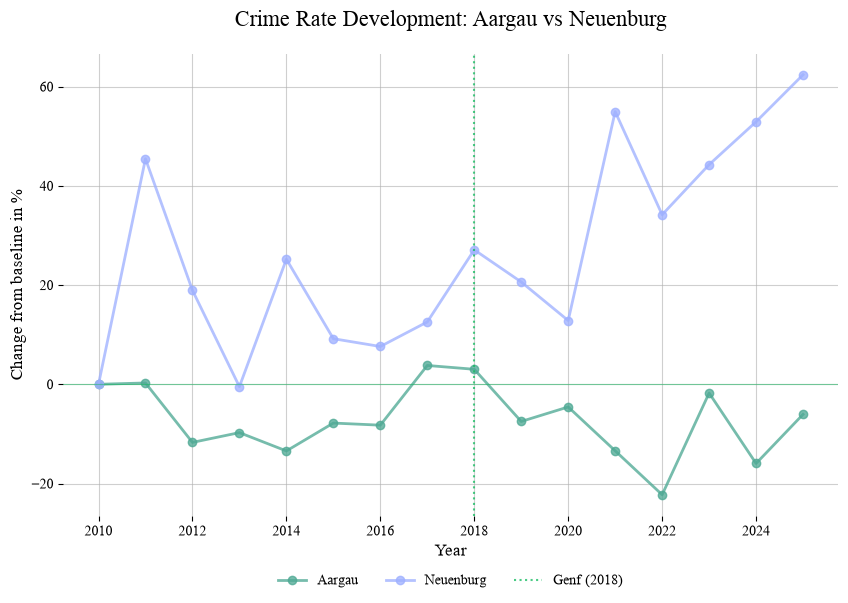

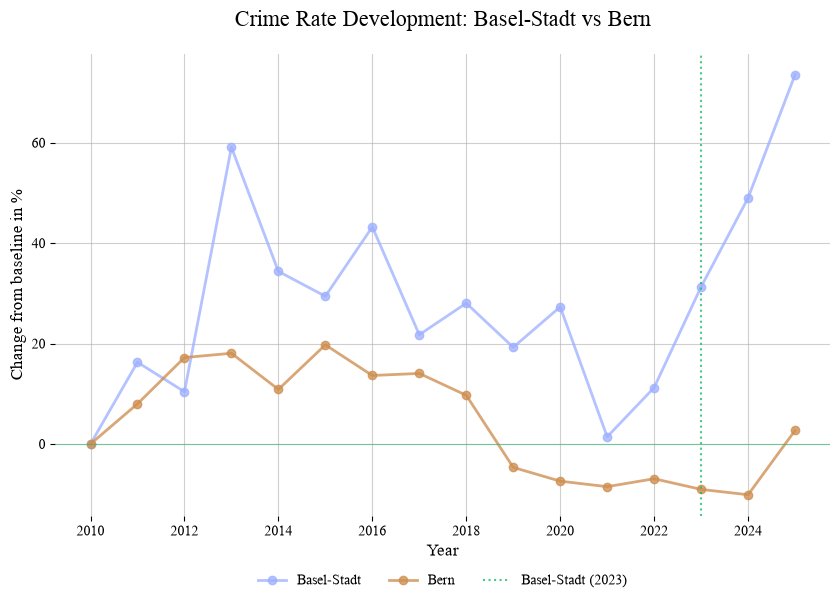

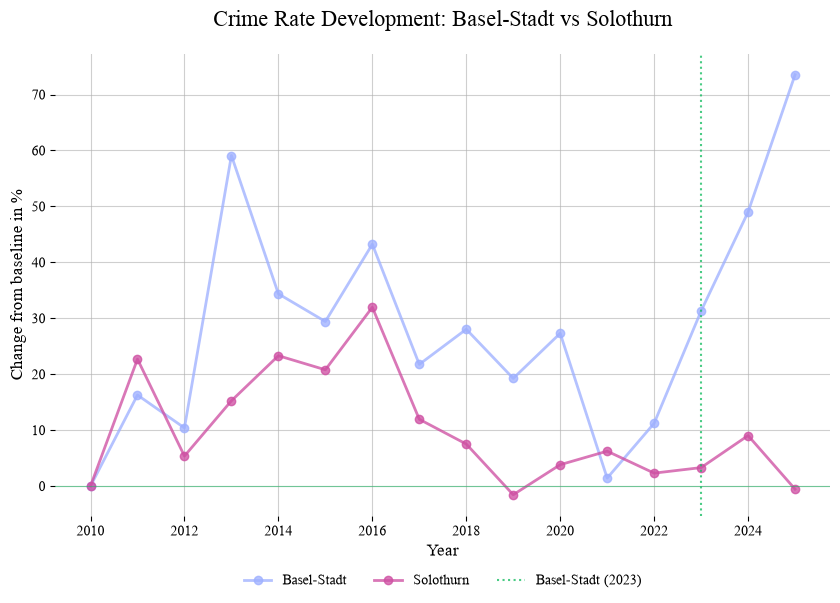

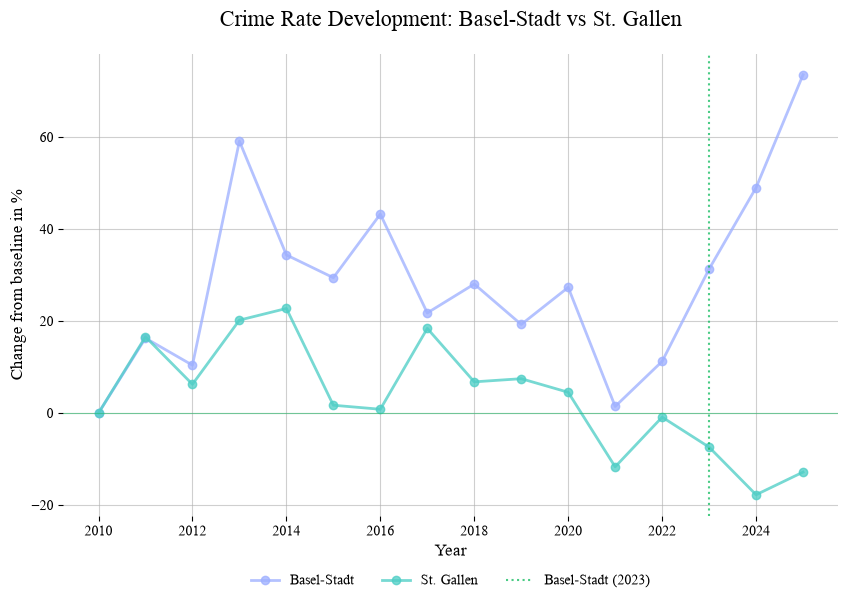

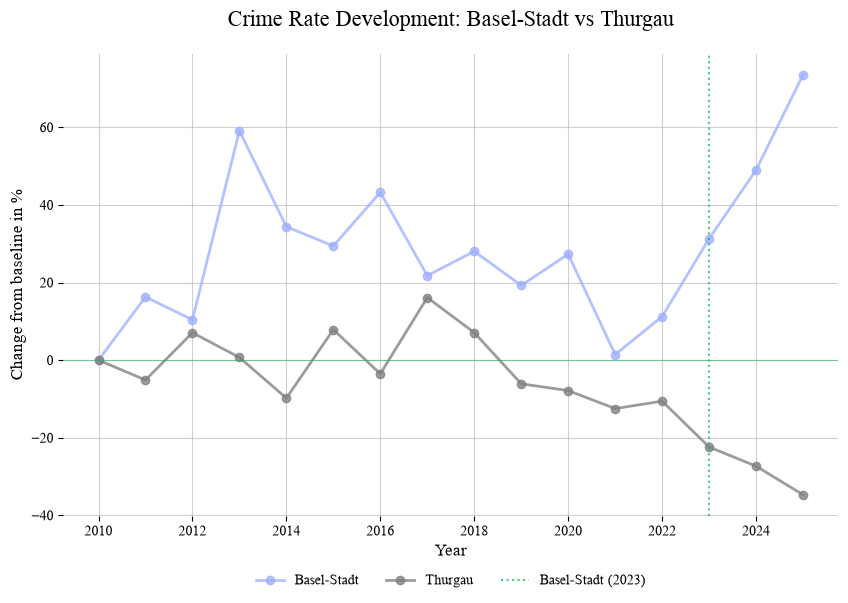

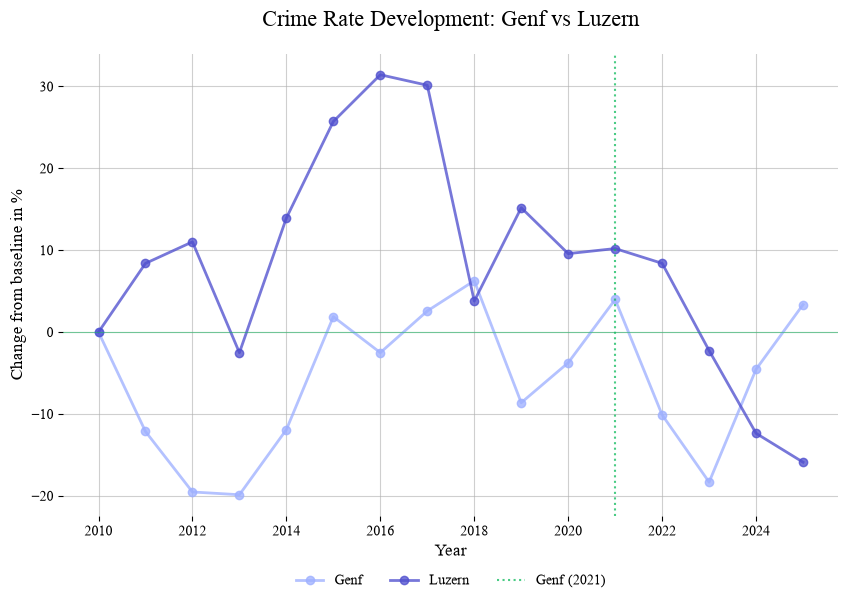

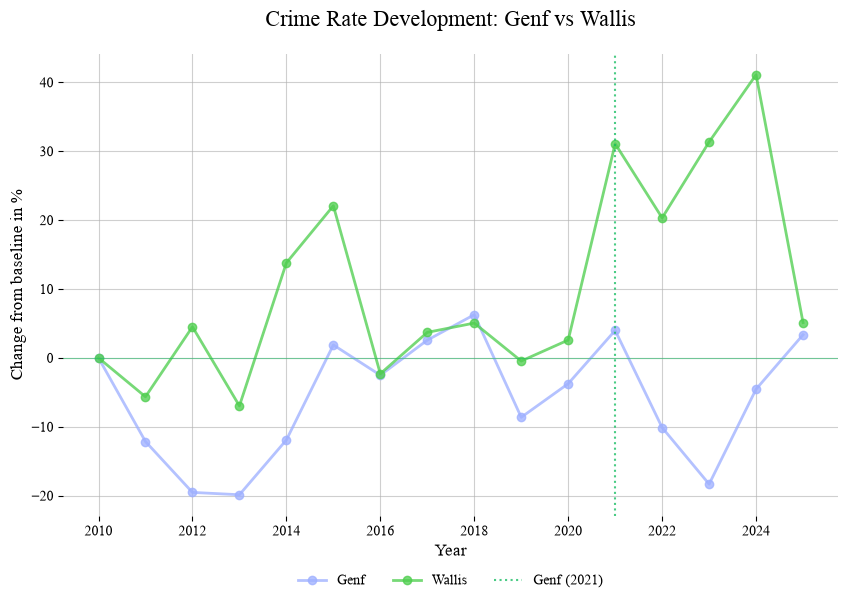

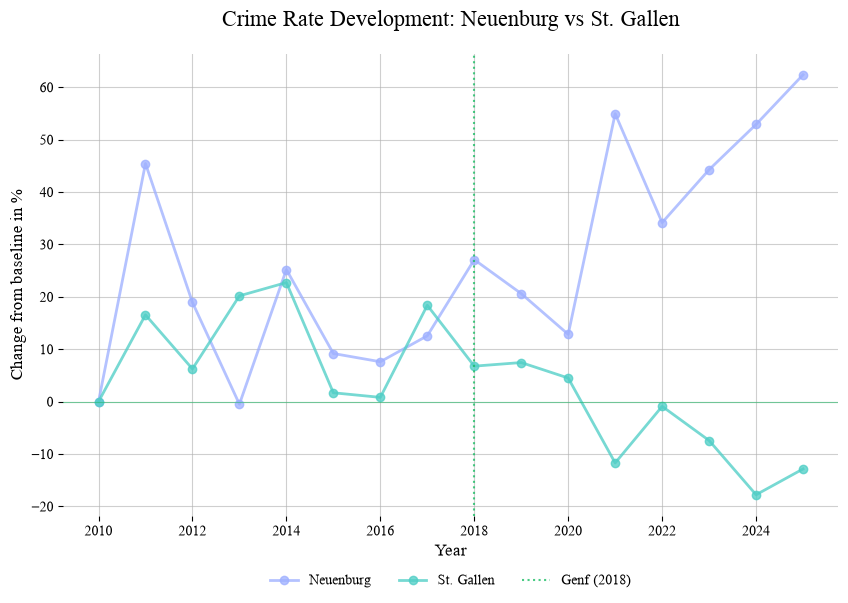

In [9]:
#WITH LOG ACCUSED RATE

plt.rcParams['font.family'] = 'Times New Roman'
colour1 = "#14BC60C5"
colour2 = "#14BC60C5"
colour_cantons = {
    "Aargau":           "#4EA994C5",  # purple
    "Basel-Stadt":      "#9EB0FFC5",  # yellow-green
    "Bern":             "#CE8E4FC5",  # orange
    "Genf":             "#9EB0FFC5",  # red
    "Luzern":           "#4F4FCEC5",  # indigo
    "Neuenburg":        "#9EB0FFC5",  # light blue
    "Solothurn":        "#CE4FA2C5",  # pink
    "St. Gallen":       "#4FCEC6C5",  # cyan
    "Thurgau":          "#7F7F7FC5",  # gray
    "Wallis":           "#4FCE4FC5",  # green
    }

for canton1, canton2 in combinations:
  
  # 1. Filtering subset for the current pair of cantons
  subset = data[data['Canton'].isin([canton1, canton2])]

  # 2. Creating canvas
  plt.figure(figsize=(10, 6))

  # 3. Ploting both cantons onto same graph
  for canton in [canton1, canton2]:
    canton_data = subset[subset['Canton'] == canton]
    base_value = canton_data['AccusedLog'].iloc[0]
    canton_data['NormalizedChange'] = ((canton_data['AccusedLog'] - base_value) / base_value) * 100

    plt.plot(
        canton_data['Year'], 
        canton_data['NormalizedChange'],
        marker='o', 
        color=colour_cantons[canton],
        linewidth=2, 
        label=canton)
  if 'Basel-Stadt' in [canton1, canton2]: #adding dotted line for minimum-wage-introduction
    plt.axvline(
      x=2023,
      color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Basel-Stadt (2023)')
  elif 'Genf' in [canton1, canton2]:
    plt.axvline(
      x=2021,
      color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Genf (2021)')
  elif 'Neuenburg' in [canton1, canton2]:
    plt.axvline(
      x=2018,
     color=colour1,
      linestyle='dotted',
      linewidth=1.5,
      label='Genf (2018)')


  

  # 4. Add titles, labels, and show the plot
  plt.title(f'Crime Rate Development: {canton1} vs {canton2}', fontsize=16, pad = 20)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel('Change from baseline in %', fontsize=12)
  plt.axhline(0, color=colour2, linewidth=0.8, linestyle='-', alpha=0.5) #adding line to see baseline
  plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.10), ncol=3, frameon=False )
  plt.grid(True, linestyle='-', alpha=0.6)
  for spine in plt.gca().spines.values():
    spine.set_visible(False)
  plt.show()